# Full-corpus Socratic tutoring with Qwen3.5-4B

Milestone 4 · English-medium NCERT classes 6–10 · November 2026

**Dataset decision.** The original training split contains 23,876 maths dialogues. The second release contains 1,500 curriculum examples, including 900 science questions (708 train, 95 validation, 97 test). All 900 have one user question and one assistant completion. The common instruction explicitly asks for direct conceptual answers. These are useful authoring seeds. An answer about regular reflection, for example, could support a dialogue where a learner compares a still lake with rippled water, explains what changed, and receives a follow-up question about the surface.

An exact comparison after lowercasing and collapsing whitespace found 294 distinct questions from the original maths test set in the mixed release’s training prompts. Combining both releases wholesale would contaminate evaluation.

The default run uses all eligible maths dialogues plus the published science training questions in one adapter. Science uses an auxiliary teacher answer-key instruction. Maths uses the student-facing Socratic instruction. Evaluate science in both modes. Reviewed multi-turn science dialogues can replace the QA data with direct practice in tutoring. The TA's proposed target is 3,000–5,000 distinct grounded dialogues.

Milestone 3 selected Qwen3.5-4B with rank 16 and a learning rate of 0.0002 on 2,000 candidate dialogues. This notebook starts fresh from the instruction model. Run top to bottom in a single-GPU Linux notebook with internet and persistent storage. Use a BF16-capable GPU if available. A T4 uses the slower float32 fallback. Preprocessing runs on CPU; actual memory use and runtime are recorded during training.

[Original dialogues](https://huggingface.co/datasets/IITM-2026T3-DSAI-GROUP2/socratic-tutoring-dataset) · [Mixed release manifest](https://huggingface.co/datasets/IITM-2026T3-DSAI-GROUP2/preprocessed_tutor_ncrtinclude_data/blob/58b86defbec43a2c8d520ee1419b7425027f7d7e/manifest.json) · [Upstream curriculum QA](https://huggingface.co/datasets/FoundryAILabs/k12-indian-curriculum-4.9m) · [Unsloth Qwen3.5 guide](https://unsloth.ai/docs/models/qwen3.5/fine-tune)

## Verified Milestone 4 run

Qwen3.5-4B completed **3,073 optimizer steps** on Kaggle T4 with a **2,048-token** context limit. The full training fit used 23,870 eligible maths dialogues and 708 science Q&A examples. The test split stayed reserved. This section records the completed Kaggle runs and is visible without executing the notebook.

### Hyperparameter selection

The four trials used the same seed and a balanced pilot of 600 training dialogues. The selected setting used the lowest monitoring loss.

| Learning rate | Weight decay | Pilot monitoring loss |
| ---: | ---: | ---: |
| 0.00005 | 0.00 | 1.2594 |
| 0.00005 | 0.01 | 1.2599 |
| 0.00020 | 0.00 | 1.1864 |
| 0.00020 | 0.01 | 1.1828 |

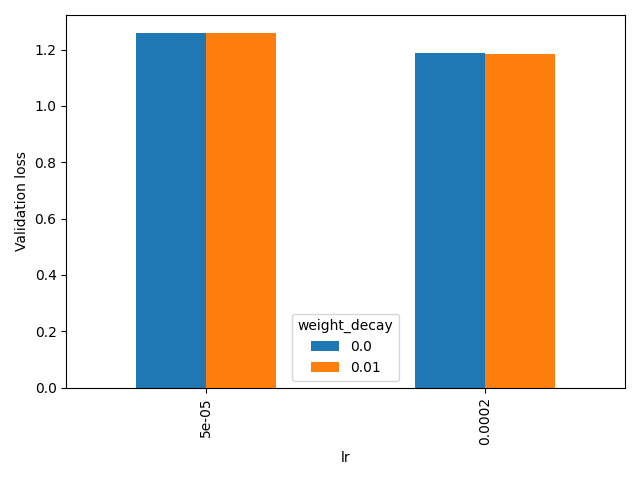

### Full-run validation

Both conditions used the same held-out validation windows, with adapter contributions disabled for the base comparison. Lower values indicate better next-token prediction.

| Source | Windows | Base loss | Tuned loss | Base perplexity | Tuned perplexity |
| --- | ---: | ---: | ---: | ---: | ---: |
| MathDial | 305 | 2.9447 | 1.7196 | 19.01 | 5.58 |
| NCERT science Q&A | 95 | 1.5086 | 1.0517 | 4.52 | 2.86 |
| SocraTeach | 2682 | 1.4564 | 0.8193 | 4.29 | 2.27 |

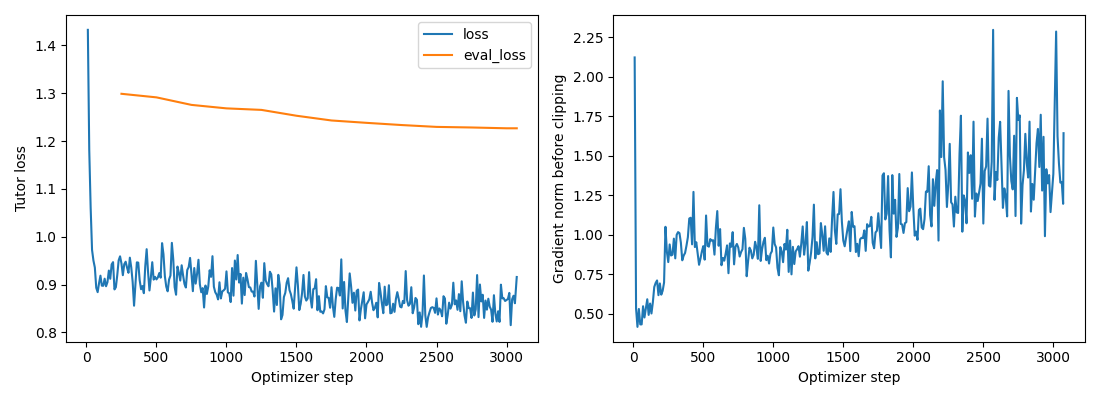

The science Q&A loss improved. On the 40 paired science prompts under the Socratic instruction, 38 base replies and 7 tuned replies contained a question mark. For the guitar-string example, the base asked the learner to reason about vibration, while the tuned model directly stated that the pitch rises. Question marks are a quick indicator. Human scoring of factual grounding, hint quality, and answer leakage remains pending.

### Saved artifacts

- The initial run saved step 2,380. [Initial Kaggle output](https://www.kaggle.com/code/hariom1407/qwen35-mixed-socratic-tutor-m4/output)
- The continuation completed training and saved `qwen35-m4/mixed-hf-qa-v2/full/adapter/` and `full/checkpoint-3073/`. Its baseline evaluation raised a Transformers quantization error after the weights were saved. [Kaggle continuation](https://www.kaggle.com/code/hariom1407/qwen35-mixed-socratic-tutor-m4-resume)
- The evaluation-only run recovered the final adapter and published `validation.csv`, `transcripts.csv` (240 rows), `science_tutor_probes.csv` (80 rows), and `learning_curves.png`. [Verified Kaggle evaluation output](https://www.kaggle.com/code/hariom1407/qwen35-mixed-socratic-tutor-m4-evaluation/output)

In [ ]:
import time

SESSION_START = time.monotonic()
%pip install -q "unsloth==2026.11.6" "unsloth_zoo==2026.11.6" "transformers==5.17.0" datasets matplotlib rouge-score

### Data and run settings

For the first Kaggle run, import this notebook, enable Internet and a T4 or newer GPU, and leave both input paths at `None`. Both datasets and the base model download automatically. To replace science QA with reviewed dialogues, set `SCIENCE_DIR` to a folder with reviewed `train.jsonl`, `val.jsonl` and `test.jsonl` for a mixed run. Each line needs `dialogue_id`, `problem_id` (shared by variants), `source="ncert_science"`, `grade` (6–10), `chapter_id` (book + chapter), `passage_id`, `passage`, `citation` (book/page or official URL), `question`, and `messages`. Use alternating student/tutor messages with `role` and `content`, at least two exchanges, and mark any telling/leaking turns using the M3 fields. Whole chapters, passages, problems and variants must stay in one split. Preserve the fixed maths splits. The notebook checks these boundaries and records a fingerprint of the supplied science files.

On Kaggle, select a T4 accelerator and enable Internet for Save & Run All. When a Kaggle run reaches the 11-hour 45-minute budget, training saves its next optimizer-step checkpoint and exits normally so Kaggle can save the output. To continue, attach the previous saved Notebook Output and set `RESUME_FROM` to its `qwen35-m4/mixed-hf-qa-v2` or `qwen35-m4/mixed-reviewed-v2` directory. Keep the same accelerator, data inputs and `OUT_ROOT`. The notebook copies the previous run into the writable working directory and continues from its latest checkpoint.

In [ ]:
import gc, gzip, hashlib, itertools, json, math, os, random, re, shutil, subprocess, sys, time
from collections import Counter
from pathlib import Path

os.environ["CUDA_VISIBLE_DEVICES"] = os.environ.get("CUDA_VISIBLE_DEVICES", "0").split(",")[0]  # one accelerator per notebook run
import pandas as pd
import torch
if torch.cuda.is_available():
    import unsloth  # apply its patches before importing Transformers
from huggingface_hub import hf_hub_download
from transformers import AutoTokenizer

ORG = "IITM-2026T3-DSAI-GROUP2"
MATH, MIX = f"{ORG}/socratic-tutoring-dataset", f"{ORG}/preprocessed_tutor_ncrtinclude_data"
MATH_REV = "6edd4d26866b857ac86c29d1a6aac37074389edf"
MIX_REV = "58b86defbec43a2c8d520ee1419b7425027f7d7e"
MODEL, MODEL_REV = "unsloth/Qwen3.5-4B", "3764fa359b9082ea5a1e4a5e3ac3aaf6e9671636"
LIMIT, SEED = 2048, 42
SCIENCE_DIR = None  # Path copied from Kaggle Input, containing train.jsonl, val.jsonl and test.jsonl
RESUME_FROM = None  # Path to this notebook version's previous mixed-run output folder
KAGGLE_WORKING = Path("/kaggle/working")
STAGE_HOURS = 11.75 if KAGGLE_WORKING.is_dir() else None
OUT_ROOT = KAGGLE_WORKING / "qwen35-m4" if KAGGLE_WORKING.is_dir() else Path("qwen35-m4")
RUN = OUT_ROOT / ("mixed-reviewed-v2" if SCIENCE_DIR else "mixed-hf-qa-v2")
DEADLINE = SESSION_START + 3600 * STAGE_HOURS if STAGE_HOURS else math.inf

if RESUME_FROM:
    previous = Path(RESUME_FROM)
    if previous.name != RUN.name:
        raise ValueError(f"Choose the previous saved {RUN.name} folder.")
    if not (previous / "run_config.json").is_file() or not (previous / "data_revisions.json").is_file():
        raise ValueError("RESUME_FROM must point to a saved mixed run directory.")
    if not RUN.exists():
        # Keep a partial copy out of the run directory so a failed copy can be retried.
        transfer = RUN.with_name(RUN.name + "-copy")
        shutil.copytree(previous, transfer, dirs_exist_ok=True)
        transfer.replace(RUN)
RUN.mkdir(parents=True, exist_ok=True)

def save(name, data):
    (RUN / name).write_text(json.dumps(data, indent=2, ensure_ascii=False), encoding="utf-8")

def records(path):
    opener = gzip.open if str(path).endswith(".gz") else open
    with opener(path, "rt", encoding="utf-8") as f:
        yield from (json.loads(line) for line in f if line.strip())

def hub(repo, rev, name):
    return hf_hub_download(repo, name, repo_type="dataset", revision=rev)

def norm(s):
    return " ".join(s.casefold().split())

In [ ]:
splits = ("train", "val", "test")
hf_science = {split: [] for split in splits}
seed_counts = {}
seed_keys = set()
for split in splits:
    counts = Counter()
    seeds = []
    for row in records(hub(MIX, MIX_REV, split + ".jsonl")):
        counts[row["source"]] += 1
        if row["source"] == "ncert_science":
            assert [m["role"] for m in row["prompt"] + row["completion"]] == ["system", "user", "assistant"]
            assert row["qkey"] not in seed_keys
            seed_keys.add(row["qkey"])
            question = row["prompt"][1]["content"].strip()
            answer = row["completion"][0]["content"].strip()
            assert question and answer
            hf_science[split].append(dict(source="ncert_science_qa", dialogue_id=row["dialogue_id"],
                problem_id="science-" + row["qkey"], question=question,
                messages=[{"role":"tutor", "content":answer}]))
            if split == "train":
                seeds.append({"seed_id": row["qkey"], "question": row["prompt"][1]["content"],
                              "answer_for_review": row["completion"][0]["content"]})
    seed_counts[split] = dict(counts)
    if split == "train":
        pd.DataFrame(seeds).to_json(RUN / "science_train_seeds.jsonl", orient="records", lines=True, force_ascii=False)
assert [seed_counts[s]["ncert_science"] for s in splits] == [708, 95, 97]
display(pd.DataFrame(seed_counts).fillna(0).astype(int))
save("mixed_release_counts.json", seed_counts)

In [ ]:
def check_science(row):
    for k in ("dialogue_id", "problem_id", "question", "chapter_id", "passage_id", "passage", "citation"):
        assert isinstance(row[k], str) and row[k].strip(), (row.get("dialogue_id"), k)
    assert row["source"] == "ncert_science" and int(row["grade"]) in range(6, 11)
    turns = row["messages"]
    assert len(turns) >= 4 and len(turns) % 2 == 0
    assert all(t["role"] == ("student", "tutor")[i % 2] and t["content"].strip() for i, t in enumerate(turns))

rows, split_keys, science_hashes = {}, {}, {}
for split in splits:
    combined = list(records(hub(MATH, MATH_REV, split + ".jsonl.gz")))
    if SCIENCE_DIR:
        file = Path(SCIENCE_DIR) / (split + ".jsonl")
        science_hashes[split] = hashlib.sha256(file.read_bytes()).hexdigest()
        science = list(records(file))
        assert science, split
        for row in science:
            check_science(row)
    else:
        science = hf_science[split]
    combined.extend(science)
    ids = [r["dialogue_id"] for r in combined]
    assert len(set(ids)) == len(ids)
    split_keys[split] = {(k, r[k]) for r in combined for k in ("dialogue_id", "problem_id", "chapter_id", "passage_id") if r.get(k)}
    split_keys[split].update(("question", norm(r["question"])) for r in combined)
    split_keys[split].update(("passage", norm(r["passage"])) for r in combined if r.get("passage"))
    if split != "test":
        rows[split] = combined
    print(split, dict(Counter(r["source"] for r in combined)))
del combined
for a, b in itertools.combinations(splits, 2):
    overlap = split_keys[a] & split_keys[b]
    assert not overlap, (a, b, list(overlap)[:3])
# Test contributes split identifiers only. No test examples enter encoding, selection or evaluation.
revisions = {"encoding_version": 2, "tokenizer_revision": MODEL_REV, "context": LIMIT, "math": MATH_REV, "seed_questions": MIX_REV, "science_sha256": science_hashes}
manifest_path = RUN / "data_revisions.json"
if manifest_path.exists() and json.loads(manifest_path.read_text()) != revisions:
    raise ValueError("The data changed. Use a new OUT_ROOT to preserve the previous run.")
save("data_revisions.json", revisions)

### Tutor targets and 2,048-token context

The problem stays at the front of every window. Student attempts, the optional private answer, the NCERT passage, and earlier replies provide context. Eligible tutor content, auxiliary teacher answer keys and their end-of-turn tokens receive loss. For a long dialogue, the next window repeats the problem and up to 256 preceding dialogue tokens. Repeated tokens are masked. Every eligible target token is counted exactly once. The length report compares the same rendered dialogues at 768 and 2,048, and separately identifies records with zero eligible targets.

**Verified on the pinned maths corpus.** Using this prompt, 981/23,876 train and 177/2,993 validation dialogues exceed 768 tokens. At 2,048 the counts are 0 and 2. The different source mix and template matter when comparing this result with the earlier 22%. Six train and seven validation dialogues contain only ineligible tutor targets.

In [ ]:
tok = AutoTokenizer.from_pretrained(MODEL, revision=MODEL_REV, use_fast=True)
assert tok.is_fast
END = "<|im_end|>"
START = "<|im_start|>"
STOP = tok.convert_tokens_to_ids(END)
assert tok.encode(END, add_special_tokens=False) == [STOP]

def messages(row):
    system = "You are a Socratic school tutor. Ask one short question or give one hint at a time. Let the learner find the answer."
    if row["source"] == "ncert_science_qa":
        system = "Write a science answer key for the teacher. Answer the question accurately in simple English."
    if row.get("reference_answer"):
        system += "\nPrivate answer for checking only: " + str(row["reference_answer"])
    if row.get("passage"):
        system += "\nTextbook evidence: " + row["passage"]
    question = row["question"]
    if row.get("student_attempt"):
        question += "\nStudent's initial attempt: " + row["student_attempt"]
    prompt = [{"role": "system", "content": system}, {"role": "user", "content": question}]
    turns = [{"role": {"student": "user", "tutor": "assistant"}[m["role"]], "content": m["content"].strip()}
             for m in row["messages"]]
    return prompt + turns

def template(msgs, generate=False):
    return tok.apply_chat_template(msgs, tokenize=False, enable_thinking=False, add_generation_prompt=generate)

def eligible(turn):
    return turn["role"] == "tutor" and turn.get("move") != "telling" and not turn.get("leaks_answer", False)

def encode(row):
    msgs = messages(row)
    prompt = template(msgs[:2])
    rendered = template(msgs)
    assert rendered.startswith(prompt)
    parts = rendered[len(prompt):].split(START)
    assert parts[0] == "" and len(parts) == len(row["messages"]) + 1, row["dialogue_id"]
    spans = []
    pos = len(prompt)
    for part, turn in zip(parts[1:], row["messages"]):
        pos += len(START) + len(part)
        if eligible(turn):
            target = turn["content"].strip() + END
            assert part.endswith(target + "\n"), row["dialogue_id"]
            spans.append((pos - 1 - len(target), pos - 1))
    enc = tok(rendered, add_special_tokens=False, return_offsets_mapping=True)
    ids = enc.input_ids
    labels = [-100] * len(ids)
    anchor = 0
    i = 0
    for j, (a, b) in enumerate(enc.offset_mapping):
        if b <= len(prompt):
            anchor = j + 1
        while i < len(spans) and a >= spans[i][1]:
            i += 1
        if i < len(spans) and b > spans[i][0] and a < spans[i][1]:
            labels[j] = ids[j]
    assert labels.count(STOP) == len(spans), row["dialogue_id"]
    return ids, labels, anchor

def windows(ids, labels, anchor, limit=LIMIT):
    if anchor >= limit - 1:
        raise ValueError("Problem/passage exceeds the context budget; shorten the grounding excerpt and rerun.")
    end = anchor
    while end < len(ids):
        start = max(anchor, end - min(256, (limit - anchor) // 2))
        new_end = min(len(ids), start + limit - anchor)
        target = [-100] * (anchor + end - start) + labels[end:new_end]
        if any(y != -100 for y in target):
            yield {"input_ids": ids[:anchor] + ids[start:new_end], "labels": target}
        end = new_end

# Force overlap and verify that masks preserve every target in order.
ids = list(range(70))
labels = [v if v >= 3 and v % 3 else -100 for v in ids]
parts = list(windows(ids, labels, 3, limit=16))
assert all(len(p["labels"]) == len(p["input_ids"]) <= 16 for p in parts)
assert [v for p in parts for v in p["labels"] if v != -100] == [v for v in labels if v != -100]

In [ ]:
from datasets import load_dataset

import pyarrow as pa
import pyarrow.parquet as pq

# Reuse complete encoded splits on resume. The folder identifies the recipe and the preceding cell checks data revisions.
encoded = {}
for split, data in rows.items():
    path = RUN / f"{split}_windows.parquet"
    audit_path = RUN / f"{split}_lengths.csv"
    if not (path.is_file() and audit_path.is_file()):
        audit_rows, batch = [], []
        schema = pa.schema([("input_ids", pa.list_(pa.int32())), ("labels", pa.list_(pa.int32())),
                            ("source", pa.string()), ("dialogue_id", pa.string())])
        temp = path.with_suffix(".tmp")
        with pq.ParquetWriter(temp, schema, compression="snappy") as writer:
            for row in data:
                ids, labels, anchor = encode(row)
                pieces = list(windows(ids, labels, anchor))
                targets = sum(v != -100 for v in labels)
                assert targets == sum(sum(v != -100 for v in p["labels"]) for p in pieces)
                batch.extend(dict(piece, source=row["source"], dialogue_id=row["dialogue_id"]) for piece in pieces)
                if len(batch) >= 128:
                    writer.write_table(pa.Table.from_pylist(batch, schema=schema))
                    batch.clear()
                audit_rows.append(dict(split=split, source=row["source"], dialogue_id=row["dialogue_id"],
                    tokens=len(ids), over768=len(ids)>768, over2048=len(ids)>LIMIT,
                    windows=len(pieces), targets=targets, no_target=targets==0))
            if batch:
                writer.write_table(pa.Table.from_pylist(batch, schema=schema))
        temp.replace(path)
        temp_audit = audit_path.with_suffix(".tmp")
        pd.DataFrame(audit_rows).to_csv(temp_audit, index=False)
        temp_audit.replace(audit_path)
    encoded[split] = load_dataset("parquet", data_files=str(path), split="train")
audit = pd.concat([pd.read_csv(RUN / f"{split}_lengths.csv") for split in rows], ignore_index=True)
audit.to_csv(RUN / "length_audit.csv", index=False)
display(audit.groupby(["split","source"]).agg(dialogues=("tokens","size"), max_tokens=("tokens","max"),
        pct_over768=("over768",lambda x: 100*x.mean()), pct_over2048=("over2048",lambda x: 100*x.mean()),
        windows=("windows","sum"), zero_targets=("no_target","sum")))

### Configuration and selection rule

| Setting | Value |
|---|---|
| Backbone | Qwen3.5-4B, 32 text layers, hidden size 2,560, 24 linear-attention and 8 full-attention layers; frozen vision tower |
| Input and output | One text window of up to 2,048 token IDs; next-token distribution over the 248,320-token vocabulary |
| Loss | Mean negative log probability of the next eligible assistant token, including turn end; padding and context use label −100 |
| Adaptation | Frozen 4-bit backbone, rank 16 / alpha 16 LoRA, language attention and MLP modules, dropout 0 |
| Optimizer | 8-bit AdamW, betas (0.9, 0.999), epsilon 1e−8, gradient norm clipped at 1.0 |
| Schedule | Cosine decay after 5% warm-up, physical batch 1, accumulation 8, one epoch per run |
| Search | Learning rates 0.00005 and 0.0002 crossed with weight decays 0 and 0.01; same seeded sample, fresh adapters |
| Selection | Lowest finite validation loss on the fixed source-balanced validation sample; save the best validation checkpoint for each run |
| Full fit | Every training window once per epoch, natural frequencies; report validation by source so the large synthetic maths corpus cannot hide science regressions |

The four pilots and the full fit share a frozen backbone. Each fit restores the initial adapter tensors and creates a fresh optimizer and scheduler. This avoids four repeated base loads and quantizations when the five fits share a session. Resuming a paused fit then restores its own optimizer and adapter checkpoint. Cached Parquet splits preserve token order and labels across sessions. The fit log estimates remaining training time from measured optimizer steps.

**Predeclared goals.** Improve on the base model's validation loss separately for each training source; keep the premature numeric-answer rate at or below 3% of checkable maths prompts. For the student-facing science probes, manually score at least 80% of reviewed validation replies as both factually grounded and eliciting student reasoning. These are proposed acceptance thresholds. ROUGE-L and the presence of a question mark describe outputs but cannot establish teaching quality. Leave the test set sealed for Milestone 5.

In [ ]:
assert torch.cuda.is_available(), "The data audit is complete. Select a CUDA GPU for the training cells."
# Limit Trainer to one visible GPU by selecting one accelerator in the notebook runtime.
assert torch.cuda.device_count() == 1, "Select a single visible GPU (CUDA_VISIBLE_DEVICES=0 before starting the kernel)."
from unsloth import FastVisionModel
from transformers import Trainer, TrainingArguments, TrainerCallback, DataCollatorForSeq2Seq, set_seed
from transformers.trainer_utils import get_last_checkpoint
from rouge_score import rouge_scorer
from importlib.metadata import version
import matplotlib.pyplot as plt

BF16 = torch.cuda.get_device_capability()[0] >= 8 and torch.cuda.is_bf16_supported()
# High-memory BF16 GPUs can retain activations and avoid recomputing them during backward.
CHECKPOINTING = False if BF16 and torch.cuda.get_device_properties(0).total_memory >= 48 * 10**9 else "unsloth"
GRID = list(itertools.product([5e-5, 2e-4], [0.0, 0.01]))
fixed = dict(model=MODEL, model_revision=MODEL_REV, math_revision=MATH_REV, seed_questions_revision=MIX_REV,
             science_sha256=science_hashes, context=LIMIT, seed=SEED, rank=16, alpha=16, dropout=0,
             batch=1, accumulation=8, epochs=1, warmup_fraction=0.05, clip=1.0, grid=GRID,
             bf16=BF16, gpu=torch.cuda.get_device_name(), recipe_version=2, gradient_checkpointing=CHECKPOINTING,
             packages={k: version(k) for k in ("unsloth","unsloth_zoo","transformers","torch","peft","bitsandbytes","datasets")})
config_path = RUN / "run_config.json"
if config_path.exists() and json.loads(config_path.read_text()) != json.loads(json.dumps(fixed)):
    raise ValueError("Output directory belongs to another configuration. Choose a new OUT_ROOT.")
save("run_config.json", fixed)
(RUN / "requirements_runtime.txt").write_text(subprocess.check_output(
    [sys.executable, "-m", "pip", "freeze"], text=True), encoding="utf-8")
print(fixed)

def sample_ids(split, per_source):
    sample = audit[(audit.split == split) & (audit.targets > 0)]
    return set(sample.sort_values("dialogue_id").groupby("source", group_keys=False)
               .apply(lambda group: group.sample(min(per_source, len(group)), random_state=SEED))["dialogue_id"])

def subset(split, ids):
    return encoded[split].filter(lambda row: row["dialogue_id"] in ids)

pilot_ids, monitor_ids = sample_ids("train", 200), sample_ids("val", 48)
pilot, monitor = subset("train", pilot_ids), subset("val", monitor_ids)
save("selection_ids.json", {"pilot": sorted(pilot_ids), "monitor": sorted(monitor_ids)})
collate = DataCollatorForSeq2Seq(tok, padding=True, pad_to_multiple_of=8, return_tensors="pt")
def inputs(dataset):
    return dataset.remove_columns(["source", "dialogue_id"])

def load_base():
    set_seed(SEED)
    model, _ = FastVisionModel.from_pretrained(
        model_name=MODEL, revision=MODEL_REV, max_seq_length=LIMIT, load_in_4bit=True,
        dtype=torch.bfloat16 if BF16 else torch.float32, use_gradient_checkpointing=CHECKPOINTING)
    return model

class Stability(TrainerCallback):
    def on_train_begin(self, args, state, control, **kwargs):
        self.started_at = time.monotonic()
        self.start_step = state.global_step

    def on_log(self, args, state, control, logs=None, **kwargs):
        for key in ("loss", "eval_loss", "grad_norm"):
            if key in (logs or {}) and not math.isfinite(logs[key]):
                raise FloatingPointError(f"{key} diverged at optimizer step {state.global_step}")

    def on_step_end(self, args, state, control, **kwargs):
        completed = state.global_step - self.start_step
        if completed > 0 and completed % 50 == 0:
            sec = (time.monotonic() - self.started_at) / completed
            print(f"{sec:.1f} s/optimizer step; estimated remaining fit time {(state.max_steps-state.global_step)*sec/3600:.2f} h")
        if state.global_step >= state.max_steps:
            control.should_log = control.should_evaluate = control.should_save = True
        elif time.monotonic() >= DEADLINE:
            control.should_log = control.should_save = control.should_training_stop = True
            control.should_evaluate = False
        return control

training_model = None
initial_adapter = {}

def fresh_adapter():
    global training_model
    set_seed(SEED)
    if training_model is not None:
        with torch.no_grad():
            for key, param in training_model.named_parameters():
                if key in initial_adapter:
                    param.copy_(initial_adapter[key])
        training_model.zero_grad(set_to_none=True)
        training_model.train()
        return training_model
    model = load_base()
    model = FastVisionModel.get_peft_model(model, r=16, lora_alpha=16, lora_dropout=0,
        finetune_vision_layers=False, finetune_language_layers=True,
        finetune_attention_modules=True, finetune_mlp_modules=True,
        use_gradient_checkpointing=CHECKPOINTING, random_state=SEED)
    adapted = [n for n,p in model.named_parameters() if p.requires_grad]
    assert adapted and all("lora_" in n and "visual" not in n and "vision_tower" not in n for n in adapted)
    initial_adapter.update({key: param.detach().cpu().clone() for key, param in model.named_parameters() if param.requires_grad})
    training_model = model
    return model

def fit(name, lr, decay, data):
    folder = RUN / name
    model = fresh_adapter()
    adapted = list(initial_adapter)
    trainable, total = model.get_nb_trainable_parameters()
    folder.mkdir(exist_ok=True)
    save(f"{name}/architecture.json", dict(trainable=trainable, total=total, adapted=adapted,
                                            text_config=model.config.text_config.to_dict()))
    steps = math.ceil(len(data)/8)
    interval = min(250, max(1, steps//4))
    args = TrainingArguments(output_dir=str(folder), learning_rate=lr, weight_decay=decay,
        per_device_train_batch_size=1, per_device_eval_batch_size=1, gradient_accumulation_steps=8,
        num_train_epochs=1, optim="adamw_8bit", adam_beta1=0.9, adam_beta2=0.999, adam_epsilon=1e-8,
        lr_scheduler_type="cosine", warmup_steps=math.ceil(0.05*steps), max_grad_norm=1.0,
        bf16=BF16, fp16=False, seed=SEED, data_seed=SEED, logging_steps=min(10,interval),
        eval_strategy="steps", eval_steps=interval, save_strategy="steps", save_steps=interval,
        load_best_model_at_end=True, metric_for_best_model="eval_loss", greater_is_better=False,
        save_total_limit=2, prediction_loss_only=True, logging_nan_inf_filter=False, report_to="none")
    trainer = Trainer(model=model, args=args, train_dataset=inputs(data), eval_dataset=inputs(monitor),
                      data_collator=collate, callbacks=[Stability()])
    save(f"{name}/training_args.json", args.to_dict())
    last = get_last_checkpoint(str(folder))
    torch.cuda.reset_peak_memory_stats()
    result = trainer.train(resume_from_checkpoint=last)
    if trainer.state.global_step < trainer.state.max_steps:
        checkpoint = get_last_checkpoint(str(folder))
        if checkpoint is None or Path(checkpoint).name != f"checkpoint-{trainer.state.global_step}":
            raise RuntimeError("The paused training step has no resumable checkpoint.")
        print(f"Paused {name} at {trainer.state.global_step}/{trainer.state.max_steps}. Resume from {checkpoint}.")
        return None
    best = trainer.state.best_metric
    assert best is not None and math.isfinite(best)
    trainer.save_model(str(folder / "adapter"))
    tok.save_pretrained(folder / "adapter")
    save(f"{name}/history.json", trainer.state.log_history)
    summary = dict(name=name, lr=lr, weight_decay=decay, monitor_loss=best,
                   best_checkpoint=trainer.state.best_model_checkpoint, steps=trainer.state.global_step,
                   peak_reserved_gib=torch.cuda.max_memory_reserved()/2**30, **result.metrics)
    save(f"{name}/summary.json", summary)
    return summary

def run_fit(name, lr, decay, data):
    summary = RUN / name / "summary.json"
    if summary.exists():
        return json.loads(summary.read_text())
    if time.monotonic() >= DEADLINE:
        print(f"Session budget reached before {name}. Continue from the saved output.")
        return None
    try:
        return fit(name, lr, decay, data)
    finally:
        gc.collect()
        torch.cuda.empty_cache()

In [ ]:
full = None
trials = []
for lr, decay in GRID:
    name = f"lr{lr:g}_wd{decay:g}"
    try:
        result = run_fit(name, lr, decay, pilot)
        if result is None:
            break
        trials.append(result)
    except FloatingPointError as e:
        trials.append(dict(name=name, lr=lr, weight_decay=decay, error=str(e), monitor_loss=None))
    pd.DataFrame(trials).to_csv(RUN / "sweep.csv", index=False)
if len(trials) == len(GRID):
    sweep = pd.DataFrame(trials)
    display(sweep)
    stable = sweep.dropna(subset=["monitor_loss"])
    assert len(stable), "Every configuration diverged. Inspect the checkpoints and logs."
    winner = stable.sort_values(["monitor_loss", "lr", "weight_decay"]).iloc[0]
    ax = stable.pivot(index="lr", columns="weight_decay", values="monitor_loss").plot.bar(ylabel="Validation loss")
    ax.figure.tight_layout()
    ax.figure.savefig(RUN / "sweep.png")
    print("Selected learning rate and decay", winner.lr, winner.weight_decay)
    full = run_fit("full", float(winner.lr), float(winner.weight_decay), encoded["train"])
    display(full)
training_model = None
initial_adapter.clear()
gc.collect()
torch.cuda.empty_cache()

### Validation and reproducible inference

Reload the pinned 4-bit base and attach the saved adapter for the tuned condition. Each model sees the same validation prompts. For HF science QA, ROUGE-L measures answer-key wording overlap and loss measures next-token prediction. Inspect `science_tutor_probes.csv` for behaviour under the Socratic prompt. Use the teacher key only for judging factual consistency. These QA rows have question-level split keys and lack chapter or textbook passage metadata. Numeric leakage checks only a single numeric private answer that the learner has yet to mention and that the question does not supply. Science leakage and factual grounding require reading the transcript against the cited passage. A historical M3 ROUGE-L of 0.331 used 100 different maths validation contexts; keep it as a reference alongside the same-prompt comparison below.

In [ ]:
from contextlib import nullcontext
from peft import PeftModel

rouge = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)
number = re.compile(r"(?<![\d./])-?\d[\d,]*(?:\.\d+)?(?!\d|\.\d|/)")

def numerals(text):
    from decimal import Decimal
    return {Decimal(m.replace(",", "")) for m in number.findall(str(text))}

def review_points():
    points = []
    chosen = sample_ids("val", 40)
    for row in rows["val"]:
        if row["dialogue_id"] not in chosen:
            continue
        turns = row["messages"]
        valid = [i for i, t in enumerate(turns) if eligible(t) and (row["source"] == "ncert_science_qa" or (i and turns[i-1]["role"] == "student"))]
        if not valid:
            continue
        i = random.Random(str(SEED) + row["dialogue_id"]).choice(valid)
        prompt = messages(row)[:2+i]
        answer = numerals(row.get("reference_answer",""))
        said = numerals(" ".join(m["content"] for m in prompt if m["role"] == "user"))
        key = next(iter(answer)) if row["source"] != "ncert_science" and len(answer)==1 and answer.isdisjoint(said) else None
        points.append((row, i, prompt, key))
    return points

@torch.inference_mode()
def reply(model, prompt):
    prompt = list(prompt)
    while True:
        ids = tok.encode(template(prompt, generate=True), add_special_tokens=False)
        if len(ids) <= LIMIT-96:
            break
        if len(prompt) <= 3:
            raise ValueError("Problem and current learner turn exceed the generation budget.")
        del prompt[2]  # keep the problem and the most recent learner turn
    x = torch.tensor([ids], device=model.device)
    y = model.generate(input_ids=x, attention_mask=torch.ones_like(x), max_new_tokens=96,
                       do_sample=False, use_cache=True, eos_token_id=STOP, pad_token_id=tok.pad_token_id)
    return tok.decode(y[0, x.shape[1]:], skip_special_tokens=True).strip()

def evaluate(name, points, model):
    model.eval()
    trainer = Trainer(model=model, data_collator=collate, args=TrainingArguments(
        output_dir=str(RUN / "evaluation"), per_device_eval_batch_size=1,
        prediction_loss_only=True, report_to="none", bf16=BF16, fp16=False))
    losses = []
    for source in sorted(set(encoded["val"]["source"])):
        group = encoded["val"].filter(lambda r: r["source"] == source)
        loss = trainer.evaluate(inputs(group))["eval_loss"]
        assert math.isfinite(loss)
        losses.append(dict(model=name, source=source, windows=len(group), val_loss=loss, perplexity=math.exp(loss)))
    FastVisionModel.for_inference(model)
    generations = []
    for row, i, prompt, key in points:
        prediction = reply(model, prompt)
        reference = row["messages"][i]["content"]
        generations.append(dict(model=name, dialogue_id=row["dialogue_id"], source=row["source"], turn=i,
            prompt=template(prompt, True), citation=row.get("citation"), reference=reference, reply=prediction,
            words=len(prediction.split()), question="?" in prediction, empty=not bool(prediction),
            numeric_leak=(key in numerals(prediction)) if key is not None else None,
            rougeL=rouge.score(reference, prediction)["rougeL"].fmeasure))
    probes = []
    for row, _, _, _ in points:
        if row["source"] == "ncert_science_qa":
            prompt = messages(dict(row, source="science_tutoring_probe"))[:2]
            probes.append(dict(model=name, dialogue_id=row["dialogue_id"], question=row["question"],
                teacher_key=row["messages"][0]["content"], student_facing_reply=reply(model, prompt)))
    return losses, generations, probes

if full is not None and time.monotonic() < DEADLINE:
    points = review_points()
    losses, generations, probes = [], [], []
    eval_model = PeftModel.from_pretrained(load_base(), str(RUN / "full" / "adapter"))
    for name in ["base", "tuned"]:
        context = eval_model.disable_adapter() if name == "base" else nullcontext()
        with context:
            scores, transcripts, probe_rows = evaluate(name, points, eval_model)
        probes.extend(probe_rows)
        losses.extend(scores)
        generations.extend(transcripts)
        gc.collect()
        torch.cuda.empty_cache()
    del eval_model
    if probes:
        pd.DataFrame(probes).to_csv(RUN / "science_tutor_probes.csv", index=False)
    metrics, examples = pd.DataFrame(losses), pd.DataFrame(generations)
    metrics.to_csv(RUN / "validation.csv", index=False)
    examples.to_csv(RUN / "transcripts.csv", index=False)
    display(metrics)
    display(examples.groupby(["model","source"]).agg(prompts=("reply","size"), checkable=("numeric_leak","count"),
            leak_rate=("numeric_leak","mean"), question_rate=("question","mean"), mean_words=("words","mean"),
            empty_replies=("empty","sum"), rougeL=("rougeL","mean")))
    display(examples[examples.model=="tuned"].sort_values("rougeL").groupby("source").head(2)[
        ["source","prompt","reference","reply","rougeL"]])
    display(examples[examples.model=="tuned"].sort_values("rougeL",ascending=False).groupby("source").head(1)[
        ["source","prompt","reference","reply","rougeL"]])
else:
    print("Validation will run after training finishes in a session with time remaining.")

In [ ]:
if full is not None and "metrics" in globals():
    history = pd.read_json(RUN / "full" / "history.json")
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for col in ["loss","eval_loss"]:
        frame = history.dropna(subset=[col])
        axes[0].plot(frame.step, frame[col], label=col)
    axes[0].legend()
    axes[0].set(xlabel="Optimizer step", ylabel="Tutor loss")
    grad = history.dropna(subset=["grad_norm"])
    axes[1].plot(grad.step, grad.grad_norm)
    axes[1].set(xlabel="Optimizer step", ylabel="Gradient norm before clipping")
    fig.tight_layout()
    fig.savefig(RUN / "learning_curves.png")
    display(metrics.pivot(index="source", columns="model", values="val_loss"))
    for trial in trials:
        if trial.get("monitor_loss") is None:
            continue
        h = pd.read_json(RUN / trial["name"] / "history.json")
        train_loss = h.dropna(subset=["loss"]).iloc[-1].loss
        val_loss = h.dropna(subset=["eval_loss"]).iloc[-1].eval_loss
        print(trial["name"], "last validation minus logged training loss", round(val_loss-train_loss, 4))
print("Artifacts:", RUN.resolve())

### Interpreting the run and submitting Milestone 4

Use `sweep.csv` and `sweep.png` to compare weight decay at the same learning rate. The last logged training loss averages recent batches; the validation loss uses fixed prompts. Review the gap alongside the gradient curve. Clipping and warm-up stay fixed, so this experiment estimates the impact of learning rate and decay only.

Compare base and tuned results in `validation.csv` and inspect both high- and low-overlap examples in `transcripts.csv`. For the mixed run, record the fraction of reviewed science replies that are grounded, elicit reasoning and avoid a premature answer, with the denominator and two annotated examples. Compare maths with the base model on identical validation IDs. Record underrepresented chapters, non-finite trials, memory use and the next change justified by these results. Published benchmarks and the M3 candidate run use other protocols; report them separately.

**Reproduction.** The validation cell loads `full/adapter/` on the pinned base and generates replies. `full/checkpoint-*/` holds resumable trainer, optimizer, scheduler and RNG states. Each trial saves its arguments, architecture, history and summary. Preserve the run directory, dataset revisions and the dependency freeze with the executed notebook.

For the course submission, use the measured results to complete the report and PDF slide deck. Include team members’ actual contributions, roll numbers, dates and their own review initials, plus an appendix recording AI prompts, tools and human verification. [Course AI policy](https://bsc-iitm.github.io/dsai-lab-project/ai_policy.html)